# 01 · Exploration des données (EDA)

**Objectif** : comprendre ce qu'il y a dans `data/jobs.db` avant d'analyser quoi que ce soit.

On répond à 5 questions : combien d'offres ? quelles colonnes sont vides ? combien ont un salaire ? sur quelles dates ? les descriptions sont-elles complètes ?

In [5]:
import sys
from pathlib import Path

# Racine du projet : fonctionne que le notebook soit lance depuis notebooks/ ou depuis la racine
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.analysis import common

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
print("Projet :", ROOT)

Projet : C:\Users\lenovo\Desktop\Tech job Market intelligent plateforme


## 1. Chargement
`only_relevant=False` pour voir **toutes** les offres, pertinentes ou non.

In [6]:
jobs = common.load_jobs(only_relevant=False)
print(f"{len(jobs)} offres, {jobs.shape[1]} colonnes")
jobs.head()

8062 offres, 31 colonnes


,id,titre_original,entreprise,lieu,zone,categorie,type_contrat,temps_travail,date,description,lien,latitude,longitude,source,pays,domaine,role_hint,keyword_collecte,collecte_at,region,ville,teletravail,salaire_mensuel_min,salaire_mensuel_max,salaire_fiable,role,niveau,langue,pertinent,salaire_m,date_offre
0,4521743364,Machine Learning Engineer (F/H),NOVENCIA Groupe,"Lyon, Rhône","[""France"", ""Auvergne-Rhône-Alpes"", ""Rhône"", ""L...",Emplois Ingénierie,permanent,NaN,2024-01-12 14:09:45,Carnet de route Novencia accompagne ses client...,https://www.adzuna.fr/details/4521743364?utm_m...,45.72035,5.08666,adzuna,fr,ai_data,ML Engineer,machine learning engineer,2026-10-08T08:29:06.421427+00:00,Auvergne-Rhône-Alpes,Lyon,0,NaN,NaN,0,ML Engineer,Unspecified,fr,2,NaN,2024-01-12 14:09:45
1,4564197432,Recherche Devops / Dataops pour mission Freelance,N.A.S.H,"8ème Arrondissement, Paris","[""France"", ""Ile-de-France"", ""Paris"", ""8ème Arr...",Unknown,NaN,NaN,2024-02-09 20:43:59,Our client is looking for a DevOps in a contex...,https://www.adzuna.fr/details/4564197432?utm_m...,48.88140,2.33650,adzuna,fr,ai_data,Data Architect,data architect,2026-10-08T08:31:52.278848+00:00,Ile-de-France,Paris,0,NaN,NaN,0,Autre,Unspecified,en,2,NaN,2024-02-09 20:43:59
2,4572747122,ML Ops Engineer - All Genders,Sanofi,"Lyon, Rhône","[""France"", ""Auvergne-Rhône-Alpes"", ""Rhône"", ""L...",Emplois Ingénierie,permanent,NaN,2024-02-17 13:54:25,Job Title: ML Ops Data Engineering - All Gende...,https://www.adzuna.fr/details/4572747122?utm_m...,45.72035,5.08666,adzuna,fr,ai_data,MLOps Engineer,MLOps,2026-10-08T08:29:56.862167+00:00,Auvergne-Rhône-Alpes,Lyon,0,NaN,NaN,0,ML Engineer,Unspecified,en,2,NaN,2024-02-17 13:54:25
3,4588799746,MLOPS - Freelance - Paris,N.A.S.H,"8ème Arrondissement, Paris","[""France"", ""Ile-de-France"", ""Paris"", ""8ème Arr...",Unknown,NaN,NaN,2024-03-01 20:42:04,"Bonjour, Nous recherchons pour un de nos clien...",https://www.adzuna.fr/details/4588799746?utm_m...,48.88140,2.33650,adzuna,fr,ai_data,MLOps Engineer,MLOps,2026-10-08T08:29:56.862167+00:00,Ile-de-France,Paris,0,NaN,NaN,0,MLOps Engineer,Unspecified,fr,2,NaN,2024-03-01 20:42:04
4,4619984515,Alternance - Marketing Digital Product Data Ma...,Schneider Electric,"Eybens, Grenoble","[""France"", ""Auvergne-Rhône-Alpes"", ""Isère"", ""G...",Emplois Ingénierie,permanent,NaN,2024-03-22 14:05:17,Vous êtes passionné(e) par le digital et aimez...,https://www.adzuna.fr/details/4619984515?utm_m...,45.17237,5.80460,adzuna,fr,ai_data,Data Architect,data architect,2026-10-08T08:31:52.278848+00:00,Auvergne-Rhône-Alpes,Eybens,0,NaN,NaN,0,Autre,Alternance,fr,2,NaN,2024-03-22 14:05:17


## 2. Valeurs manquantes
Une colonne très vide est peu exploitable (souvent le salaire).

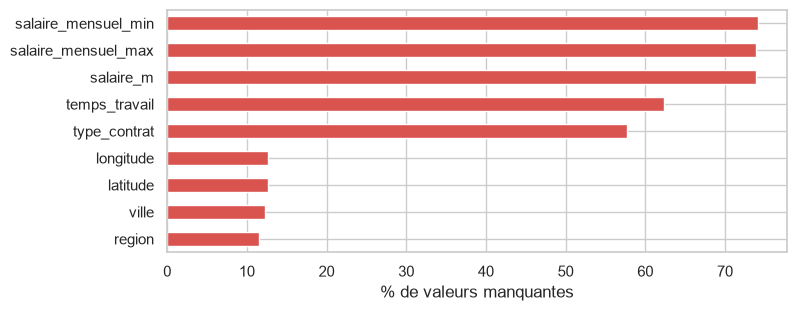

In [7]:
missing = jobs.isna().mean().mul(100).round(1).sort_values(ascending=False)
missing = missing[missing > 0]
if missing.empty:
    print("Aucune valeur manquante.")
else:
    ax = missing.plot.barh(figsize=(8, max(2, 0.35 * len(missing))), color="#d9534f")
    ax.set_xlabel("% de valeurs manquantes")
    ax.invert_yaxis()
    plt.show()

## 3. Pertinence des offres
`pertinent` : 0 = hors sujet, 1 = titre OK, 2 = titre + description OK.

,offres
pertinent,
0,3751
1,1870
2,2441


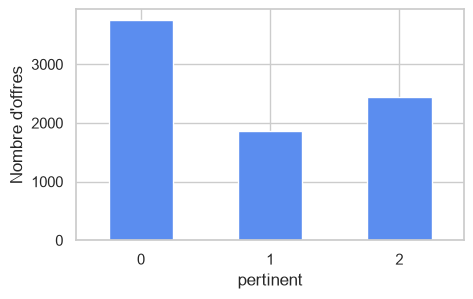

In [8]:
if "pertinent" in jobs.columns:
    counts = jobs["pertinent"].value_counts().sort_index()
    display(counts.to_frame("offres"))
    counts.plot.bar(rot=0, color="#5b8def", figsize=(5, 3))
    plt.ylabel("Nombre d'offres"); plt.show()
else:
    print("Pas de colonne `pertinent`.")

## 4. Sources des offres

In [9]:
source_col = next((c for c in jobs.columns if c.lower() in ("source", "origine", "provider")), None)
if source_col:
    display(jobs[source_col].value_counts().to_frame("offres"))
else:
    print("Pas de colonne source : ajoute-en une quand tu integres France Travail.")

,offres
source,
adzuna,8062


## 5. Salaires
La colonne est détectée automatiquement (`common.detect_salary`). Les valeurs hors de 800–20 000 €/mois sont ignorées.

Offres avec salaire : 2107 / 8062 (26 %)
count     2107.0
mean      4115.0
std       2151.0
min        800.0
25%       2916.0
50%       3750.0
75%       4833.0
max      18125.0


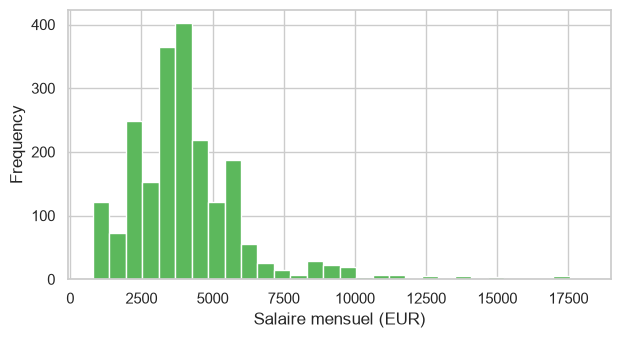

In [10]:
sal = jobs["salaire_m"].dropna()
print(f"Offres avec salaire : {len(sal)} / {len(jobs)} ({len(sal) / len(jobs) * 100:.0f} %)")
if len(sal):
    print(sal.describe().round(0).to_string())
    sal.plot.hist(bins=30, figsize=(7, 3.5), color="#5cb85c")
    plt.xlabel("Salaire mensuel (EUR)"); plt.show()

## 6. Dates
Sans plusieurs dates différentes, impossible de mesurer une tendance.

Du 2024-01-12 au 2026-10-08 (999 jours)


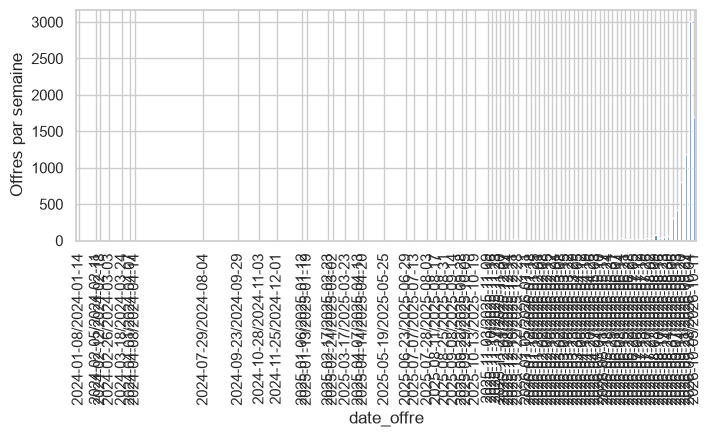

In [11]:
dates = jobs["date_offre"].dropna()
if dates.empty:
    print("Aucune date exploitable : voir DATE_COL dans common.py")
else:
    print(f"Du {dates.min():%Y-%m-%d} au {dates.max():%Y-%m-%d} ({(dates.max() - dates.min()).days} jours)")
    dates.dt.to_period("W").value_counts().sort_index().plot(kind="bar", figsize=(8, 3))
    plt.ylabel("Offres par semaine"); plt.show()

## 7. Longueur des descriptions
Si beaucoup de descriptions s'arrêtent à la même longueur (ex. 500 caractères), elles sont **tronquées** : on rate des compétences.

count    8062.0
mean      499.0
std        12.0
min       104.0
25%       500.0
50%       500.0
75%       500.0
max       500.0

Longueurs les plus frequentes :
description
500    7760
499     187
498      49


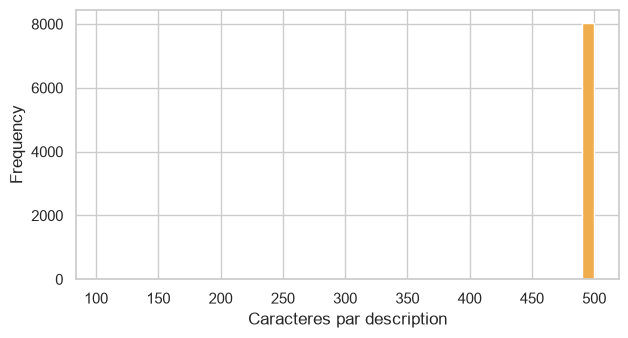

In [12]:
length = jobs["description"].fillna("").str.len()
print(length.describe().round(0).to_string())
top = length.value_counts().head(3)
print("\nLongueurs les plus frequentes :")
print(top.to_string())
length.plot.hist(bins=40, figsize=(7, 3.5), color="#f0ad4e")
plt.xlabel("Caracteres par description"); plt.show()

## À retenir
- Colonnes trop vides → à ne pas utiliser, ou à compléter avec France Travail.
- Part d'offres avec salaire < 30 % → présenter les salaires avec prudence.
- Une seule date → relancer la collecte régulièrement.
- Descriptions tronquées → intégrer France Travail pour de meilleures descriptions.